# Integrative Industry Synthesis: ML, GenAI, and Agentic
## In this notebook (Step-4)
- We collect some test results from running our agentic-workflow

# Setup

## Import required modules

In [1]:
from pathlib import Path
import time
import sys
SRC_DIR = str(Path.cwd().parent /'src')
if SRC_DIR not in sys.path:
    sys.path.append(SRC_DIR)
notebook_start_time = time.time() # Start the global timer
print(f'notebook_start_time={time.ctime(notebook_start_time)}')

notebook_start_time=Mon Oct 12 13:41:11 2026


In [2]:
import importlib
from config import settings, get_test_case_info_df
import utils as ut #use importlib.reload(ut) if reload needed in specific cell during development
import utils_gen as ut_gen
from tools.transaction_db_tools import get_transaction_df
from tools.ltm_db_tools import get_top_n_context_for_human
import seaborn as sns
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib # for version check
import matplotlib.pyplot as plt
import torch
from collections import Counter
import joblib
from tqdm.notebook import tqdm
import pprint
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    fbeta_score,
)

from IPython.display import clear_output, display, Image

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
# Enable high-resolution Retina plots
%config InlineBackend.figure_format = 'retina'

In [3]:
print("*" * 75)
print(f'PYTHON VERSION:      {sys.version}')
print(f'PYTHON VPATH:        {sys.executable}')
print(f"Pandas version:      {pd.__version__}")
print(f"NumPy version:       {np.__version__}")
print(f"Matplotlib version:  {matplotlib.__version__}")
print(f"Seaborn version:     {sns.__version__}")
print("*" * 75)

***************************************************************************
PYTHON VERSION:      3.13.14 (main, Jul 23 2026, 14:44:45) [Clang 22.1.3 ]
PYTHON VPATH:        /home/max/x/zc07-ml-genai-agentic/.venv/bin/python
Pandas version:      2.3.3
NumPy version:       2.5.3
Matplotlib version:  3.11.2
Seaborn version:     0.13.2
***************************************************************************


In [4]:
print(f'Torch version: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
print(f'CUDA version used: {torch.version.cuda}')

Torch version: 2.14.1+cu130
CUDA available: True
CUDA version used: 13.0


In [5]:
def seed_all(seed:int=42):
    """
    set random seed and cuda related settings for reproducibility
    Args:
        seed: int setting the seed
    Return:
        None
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # Handles CPU and CUDA automatically in modern PyTorch
    # Optional: Only configure CUDA/cuDNN if a GPU is actually present
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    
seed_all(settings.RANDOM_SEED)

# Command Line Options

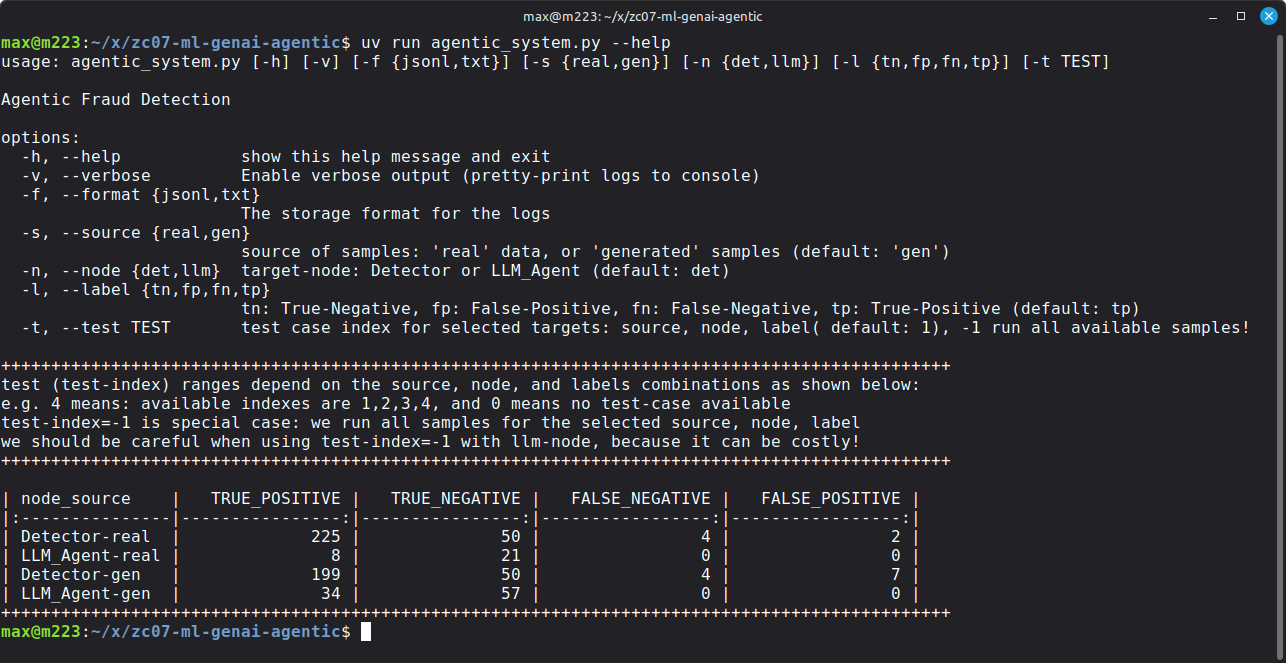

In [6]:
display(Image(filename=settings.IMG_DIR/'z-help.png', width=1200))

# First-Time Run
- First-time run means there is no database, or when we delete the entire out folder
- In this case, the system first check and will create and initiaialze all required database
- For transaction, and checkpoint only table created
- For Long-Term Memory(LTM), we initiate the Chroma Vector-dB, and initialize it with prepared training data at step-3
- Also the workflow-graph saved as shown below

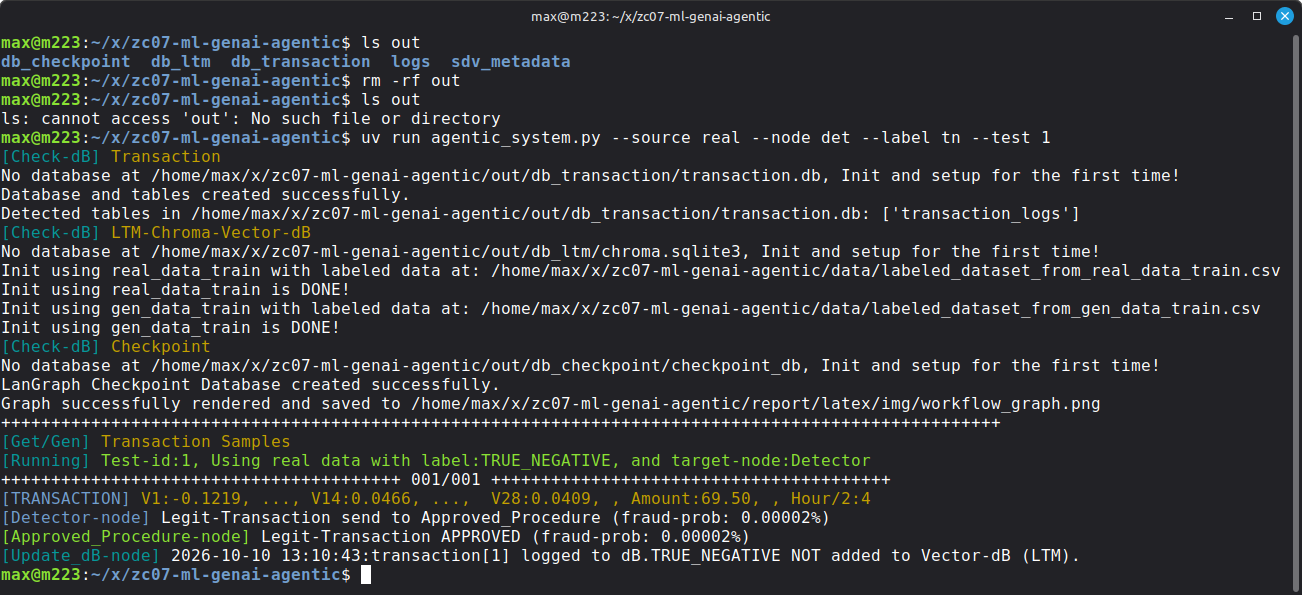

In [7]:
display(Image(filename=settings.IMG_DIR/'z-first-run.png', width=1200))

### NOTE:
- The text-output is very descriptive and shows all steps
- This is TN sample, that can be detected in detector node by the trained ML classifier
- It is flagged as Legit, and send for approval
- The approved procedure node will take care of approval procedure.
- All transaction will be logged into transaction-dB (including both actual and predicted labels for later analysis),
- We do not save True Negative label in LTM (all other label will be save in LTM)

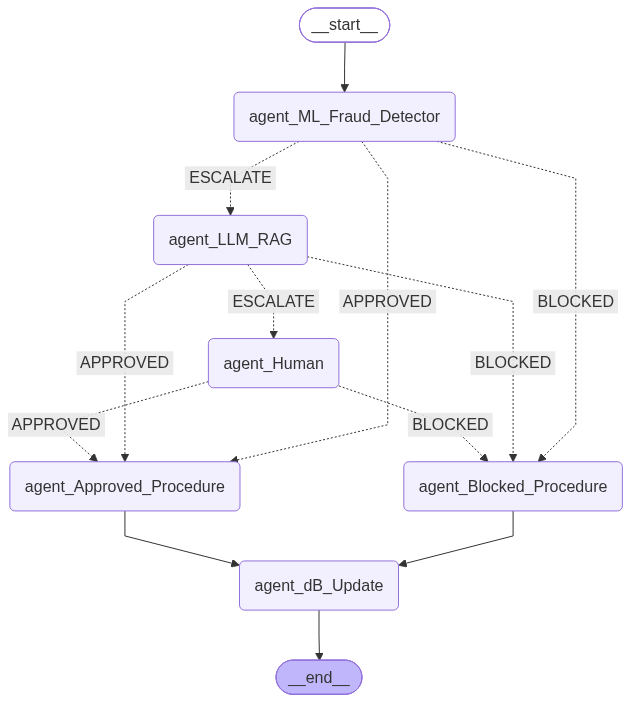

In [8]:
display(Image(filename=settings.IMG_DIR/'workflow_graph.png', width=640))

# Invalid Test-Index
- Valid test-index are 1 to max value shown in the table provided in the help menu
- For example Foe Node=Detector, and Source=gen (generated data),and label = tp (TRUE_POSITIVE) this max is 199
- When Node is LLM_Agent (llm), There is no FP or FN test-case (max-index =0)
- For Detector we have ML-classifier and we already know which samples classified as TP/TN/FP/FN
- But for LLM-Agent we only know that we have TP and TN samples (escalate from ML/Detector node), how LLM classify them is still unknown, and we do not have FN/FP samples for LLM 'yet'.

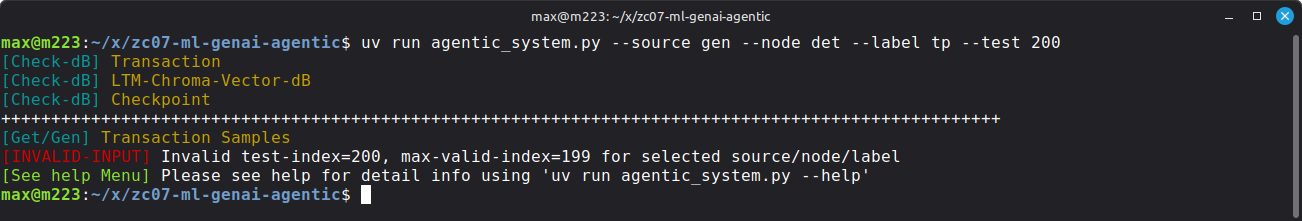

In [9]:
display(Image(filename=settings.IMG_DIR/'z-invalid-index.png', width=1000))

# Sample run for Detector Node with label: TP, FP, and FN
- TN: already shown in first run (above)
- TP: source: gen (generated data), node = det (Detector = ML-Classifier), label: tp (True-Positive), test: 17
- FP: source: real (real data), node = det (Detecto r= ML-Classifier), label: fp (False-Positive), test: 2
- FN: source: gen (generated data), node = det (Detector = ML-Classifier), label: tn (False-Negative), test: 1

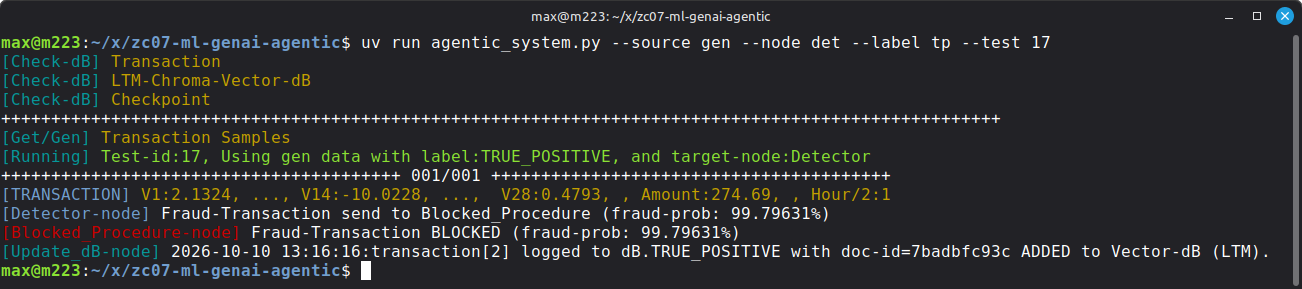

In [10]:
display(Image(filename=settings.IMG_DIR/'z-det-tp.png', width=1200))

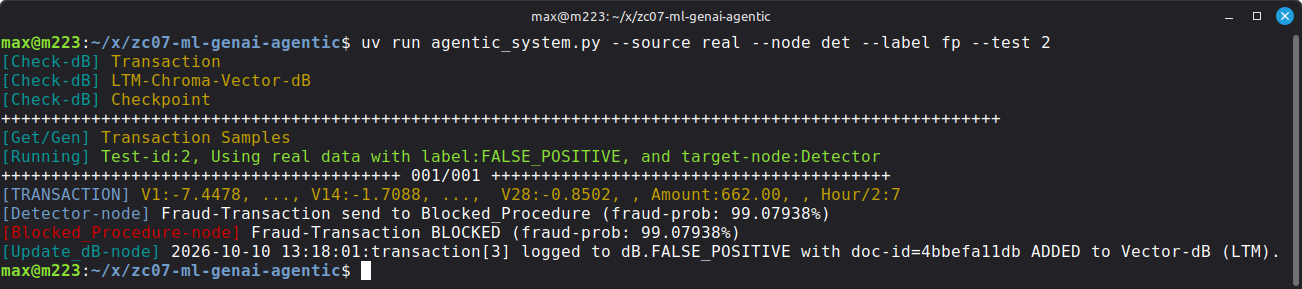

In [11]:
display(Image(filename=settings.IMG_DIR/'z-det-fp.png', width=1200))

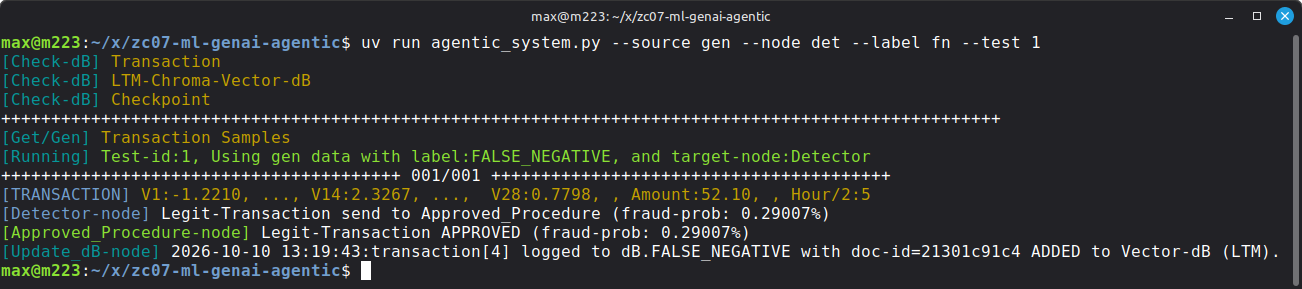

In [12]:
display(Image(filename=settings.IMG_DIR/'z-det-fn.png', width=1200))

# Three Questions and answers
The above FP and FN cases are added to LTM, If we run the same test-case

---
## Questions
1. Is LTM helpful in next run ?
2. Is LTM keep adding redundant data ?
3. Detector wrongly decided on FP/FN, what data got to transaction dB, and how LTM add correct label as FP/FN ?

## Answers
1. No, in Detector Node, we do not use any LTM, and we only use ML-Classifier, It will keep making same decision (mistake) on same data, However using dual thresholds has already reduced the FP/FN, as explained both in confusion-matrix and numerical values in step-3.
2. No When we add data to LTM, we defined a unique-id based on the transaction-data, and same transaction-data provide same unique-id (please see the code), and when we add to Vector-dB we used `upsert` instead of `add` which just update the content of existing ID, in the console output we show if ADDED or UPDATED (as shown in next cell, please check doc-id is the same, first time ADDED, second time Updated)
3. Since we use existing real dataset or we use generative models to generate Legit/Fraud samples, we always know the actual_class, so in transaction database we always add both actual_class and pred_class, for analytical purpose, also when adding to LTM, we use actual_class (which result in corresponding correct label). In reality these actual_label may need to be written, updated after human review, but in our case it is automated in update-database-node.


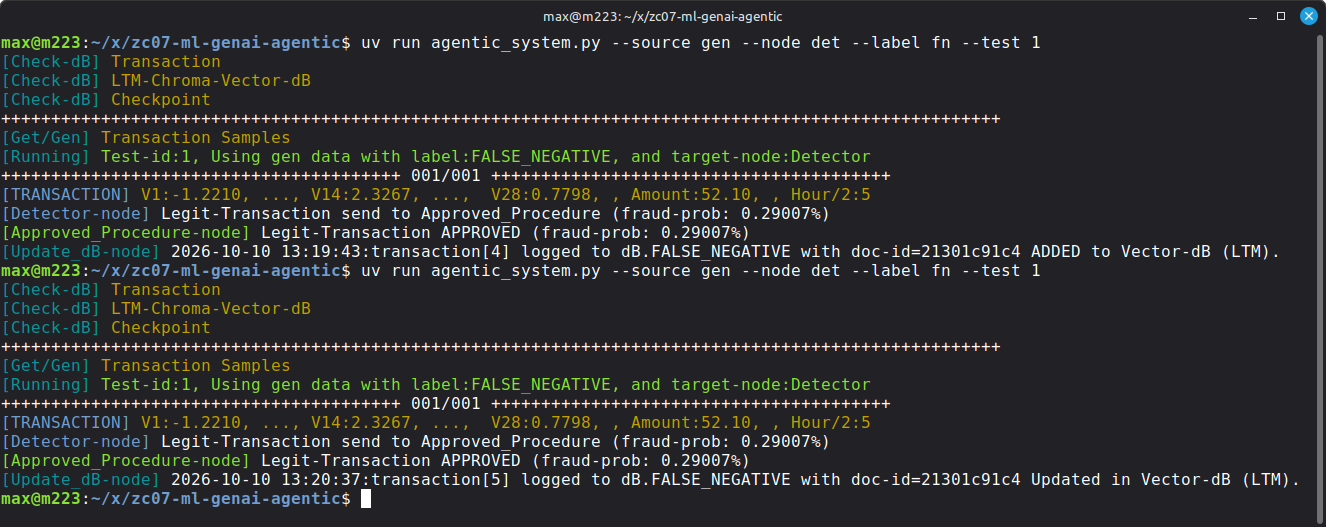

In [13]:
display(Image(filename=settings.IMG_DIR/'z-det-fn-rep.png', width=1200))

# Sample runs for LLM Node with label: TP, TN
- We try some samples
- We also repeat some sample to see the effect of LTM

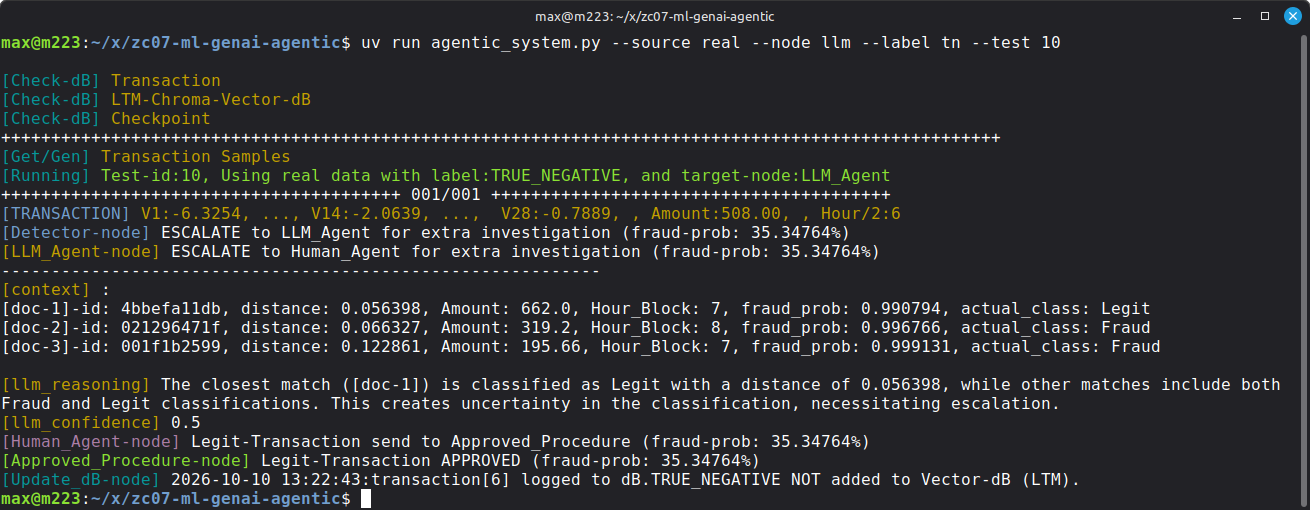

In [14]:
display(Image(filename=settings.IMG_DIR/'z-llm-real-tn-10.png', width=1200))

### Note:
- This is indeed very difficult situation
- where the first two context are very similar (both distance, and fraud probability)
- with one legit and the other as fraud
- Not simple even for human, expected to escalate

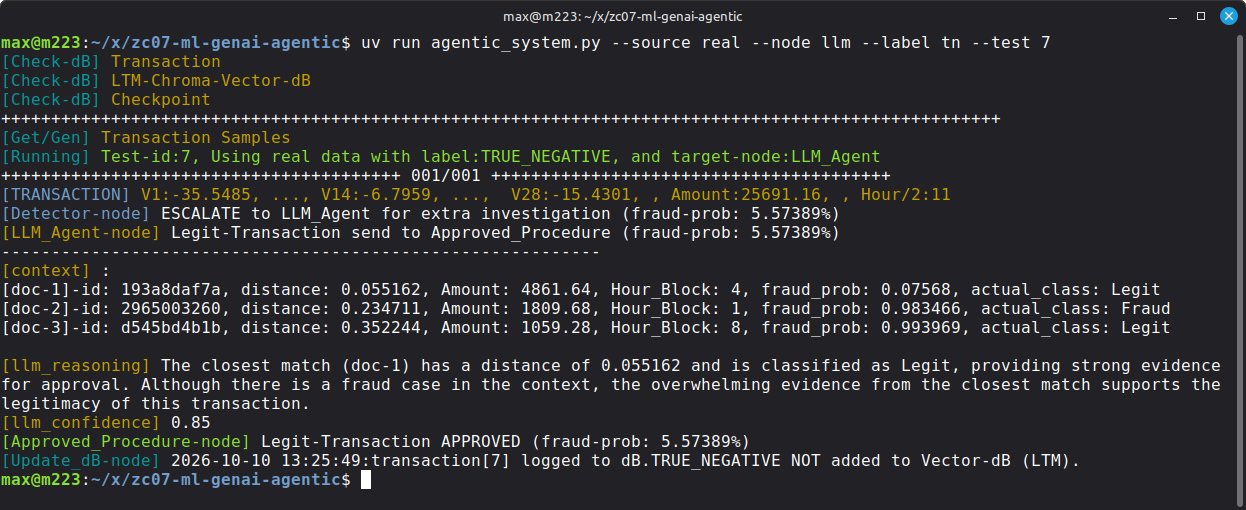

In [15]:
display(Image(filename=settings.IMG_DIR/'z-llm-real-tn-07.png', width=1200))

### Note
- Good reasoning by LLM

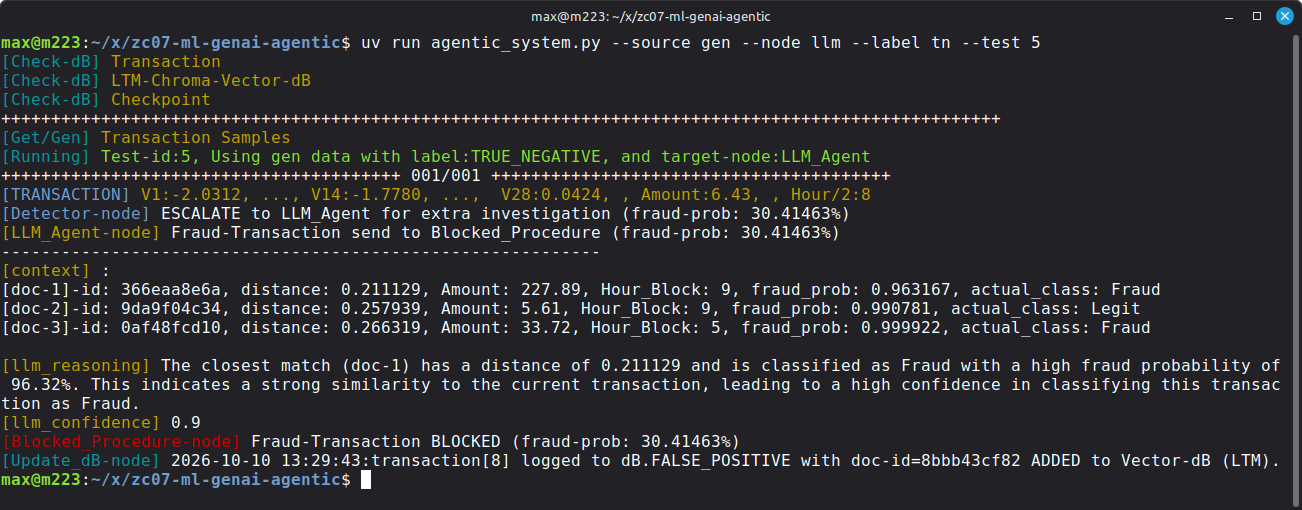

In [16]:
display(Image(filename=settings.IMG_DIR/'z-llm-gen-tn-05.png', width=1200))

### Note: FALSE-POSITIVE Created by LLM-Agent
- Having close distance, and high fraud-probability of fraud on 2 out of 3, cause agent mistake and create FALSE-POSITIVE

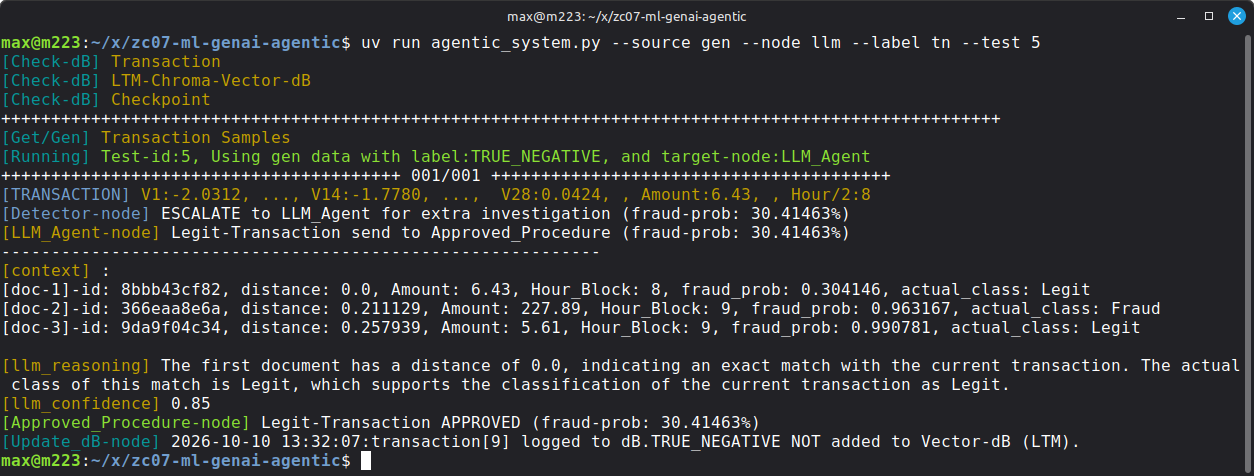

In [17]:
display(Image(filename=settings.IMG_DIR/'z-llm-gen-tn-05-rep1.png', width=1200))

### Note: Effect of LTM on guiding LLM on its previous mistake
- Having distance zero (or close to zero), help LLM-Agent to have better decision

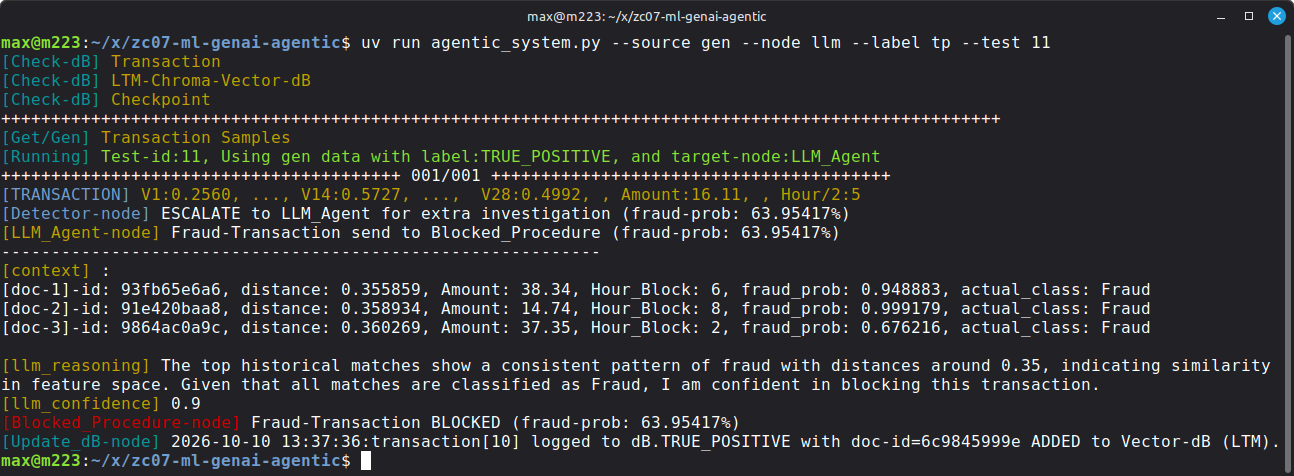

In [18]:
display(Image(filename=settings.IMG_DIR/'z-llm-gen-tp-11.png', width=1200))

### Note
- Not ambiguous, and since TP, it is also added to LTM

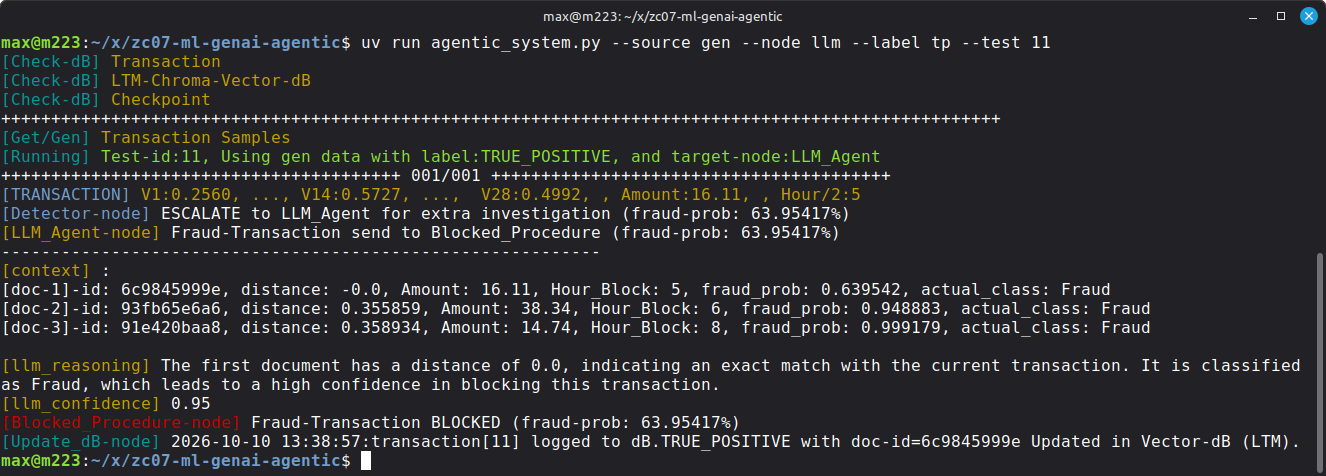

In [19]:
display(Image(filename=settings.IMG_DIR/'z-llm-gen-tp-11-rep1.png', width=1200))

### Note
- Initially was not ambiguous, and now agent is more confident (LTM just updated the same doc-id)

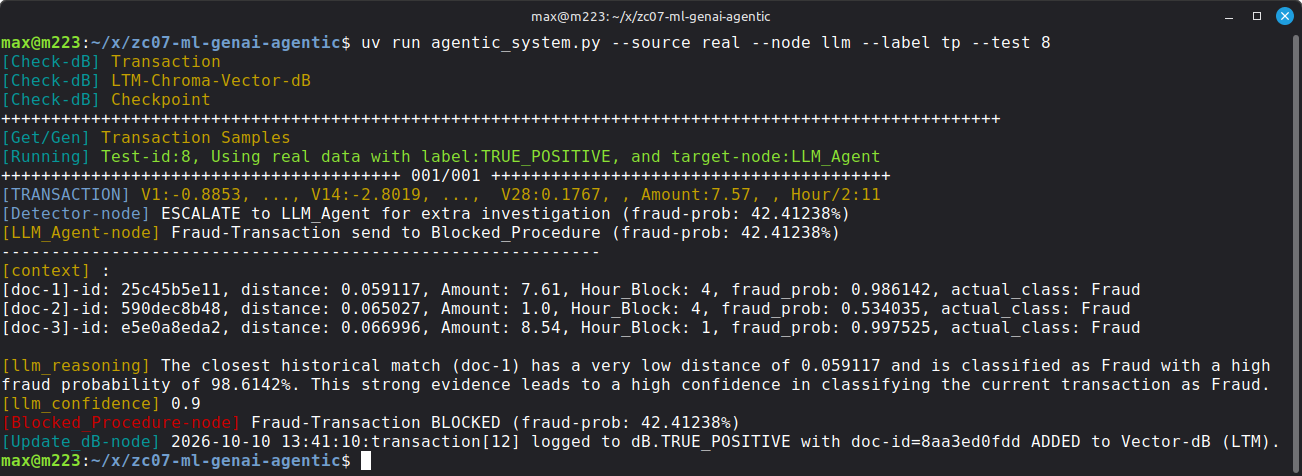

In [20]:
display(Image(filename=settings.IMG_DIR/'z-llm-real-tp-08.png', width=1200))

### Note
- Testin TP on LLM_Agent with sample from real data (not a difficult case for LLM-Agent !)

# Test Case Count Info

In [21]:
dfix = get_test_case_info_df()
dfix=dfix.set_index('node_source')
dfix['Test_Case_Count']=dfix.sum(axis=1)
dfix.loc['Column_Sum'] = dfix.sum(numeric_only=True)
dfix

,TRUE_POSITIVE,TRUE_NEGATIVE,FALSE_NEGATIVE,FALSE_POSITIVE,Test_Case_Count
node_source,,,,,
Detector-real,225,50,4,2,281
LLM_Agent-real,8,21,0,0,29
Detector-gen,199,50,4,7,260
LLM_Agent-gen,34,57,0,0,91
Column_Sum,466,178,8,9,661


In [22]:
# Markdown version for README
# a=dfix.to_markdown(index=True)
# print(a)

### Get all test-case data
- Put all test data from real-dataset and gen-dataset together for comparison with Agentic workflow

In [23]:
thx = 0.1 # single (~optimal thresold)
# Define conditions for vectorization
def get_conditions(df_src: pd.DataFrame, thx: float = 0.1, include_llm:bool=True):
    conditions = [
        # Detector conditions
        (df_src['node'] == 'Detector') & (df_src['fraud_prob'] < settings.LOW_THR),
        (df_src['node'] == 'Detector') & (df_src['fraud_prob'] > settings.HIGH_THR),
        # Non-Detector (LLM_Agent etc.) conditions
        (df_src['node'] != 'Detector') & (df_src['fraud_prob'] <= thx),
        (df_src['node'] != 'Detector') & (df_src['fraud_prob'] > thx)
    ]
    if include_llm:
        return conditions
    else:
        return conditions[:2]

# Corresponding classes for each condition
choices = [0, 1, 0, 1]

source_id = 'real'
file_path = settings.DATA_DIR/f'labeled_dataset_from_{source_id}_data_test.csv'
df_real=pd.read_csv(file_path, usecols = ['Class', 'fraud_prob', 'label', 'node'])
df_real=df_real.rename(columns={'Class': 'actual_class'})

source_id = 'gen'
file_path = settings.DATA_DIR/f'labeled_dataset_from_{source_id}_data_test.csv'
df_gen=pd.read_csv(file_path, usecols = ['Class', 'fraud_prob', 'label', 'node'])
df_gen=df_gen.rename(columns={'Class': 'actual_class'})

#source=all
df_real_gen = pd.concat([df_real, df_gen]).reset_index(drop=True)

# Run All Test Cases
- In total we have 225+8+199+34+50+21+50+57+4+4+2+7 = 661 test cases

In [24]:
# We can check the log for first run
!cat ../data/run_all_test_log_cleaned.txt | grep "run_all_test\|finished"

max@m223:~/x/zc07-ml-genai-agentic$ ./run_all_test.sh det
Script finished in 8m 17s (Total: 497 seconds).
max@m223:~/x/zc07-ml-genai-agentic$ ./run_all_test.sh llm
Script finished in 15m 11s (Total: 911 seconds).


In [25]:
# Also we can check the log for second run
!cat ../data/run_all_test_log2_cleaned.txt | grep "run_all_test\|finished"

max@m223:~/x/zc07-ml-genai-agentic$ ./run_all_test.sh det
Script finished in 9m 44s (Total: 584 seconds).
max@m223:~/x/zc07-ml-genai-agentic$ ./run_all_test.sh llm
Script finished in 15m 6s (Total: 906 seconds).


In [26]:
# We can get and save db like below, but in this notebook we use the saved data
#df = get_transaction_df()
#df.to_csv(settings.DATA_DIR/'all_test_case_runx2_trans_db.csv', index = False)
df = pd.read_csv(settings.DATA_DIR/'all_test_case_runx2_trans_db.csv')
print(df.shape)
df.iloc[:,np.r_[0:4,-7:0]].head()

(1322, 35)


,index,timestamp,V1,V2,V27,V28,Amount,HourT,actual_class,pred_class,source_id
0,1,2026-10-10 13:49:22.947978,-0.121876,-0.371387,0.033161,0.040867,69.50,4,0,0,real
1,2,2026-10-10 13:49:23.374261,1.968480,-0.461075,0.045268,-0.045286,1.00,10,0,0,real
2,3,2026-10-10 13:49:23.841096,2.043776,-0.094650,-0.073732,-0.073163,0.89,8,0,0,real
3,4,2026-10-10 13:49:24.326238,-4.066862,-5.081215,-0.057777,-0.532404,355.51,0,0,0,real
4,5,2026-10-10 13:49:24.824281,1.505781,-1.366895,0.027691,0.017529,49.95,11,0,0,real


In [27]:
L=len(df)
L2 = L //2
df1=df.iloc[:L2,:].copy()
print(df1.shape)
df2=df.iloc[L2:,:].copy()
print(df2.shape)

(661, 35)
(661, 35)


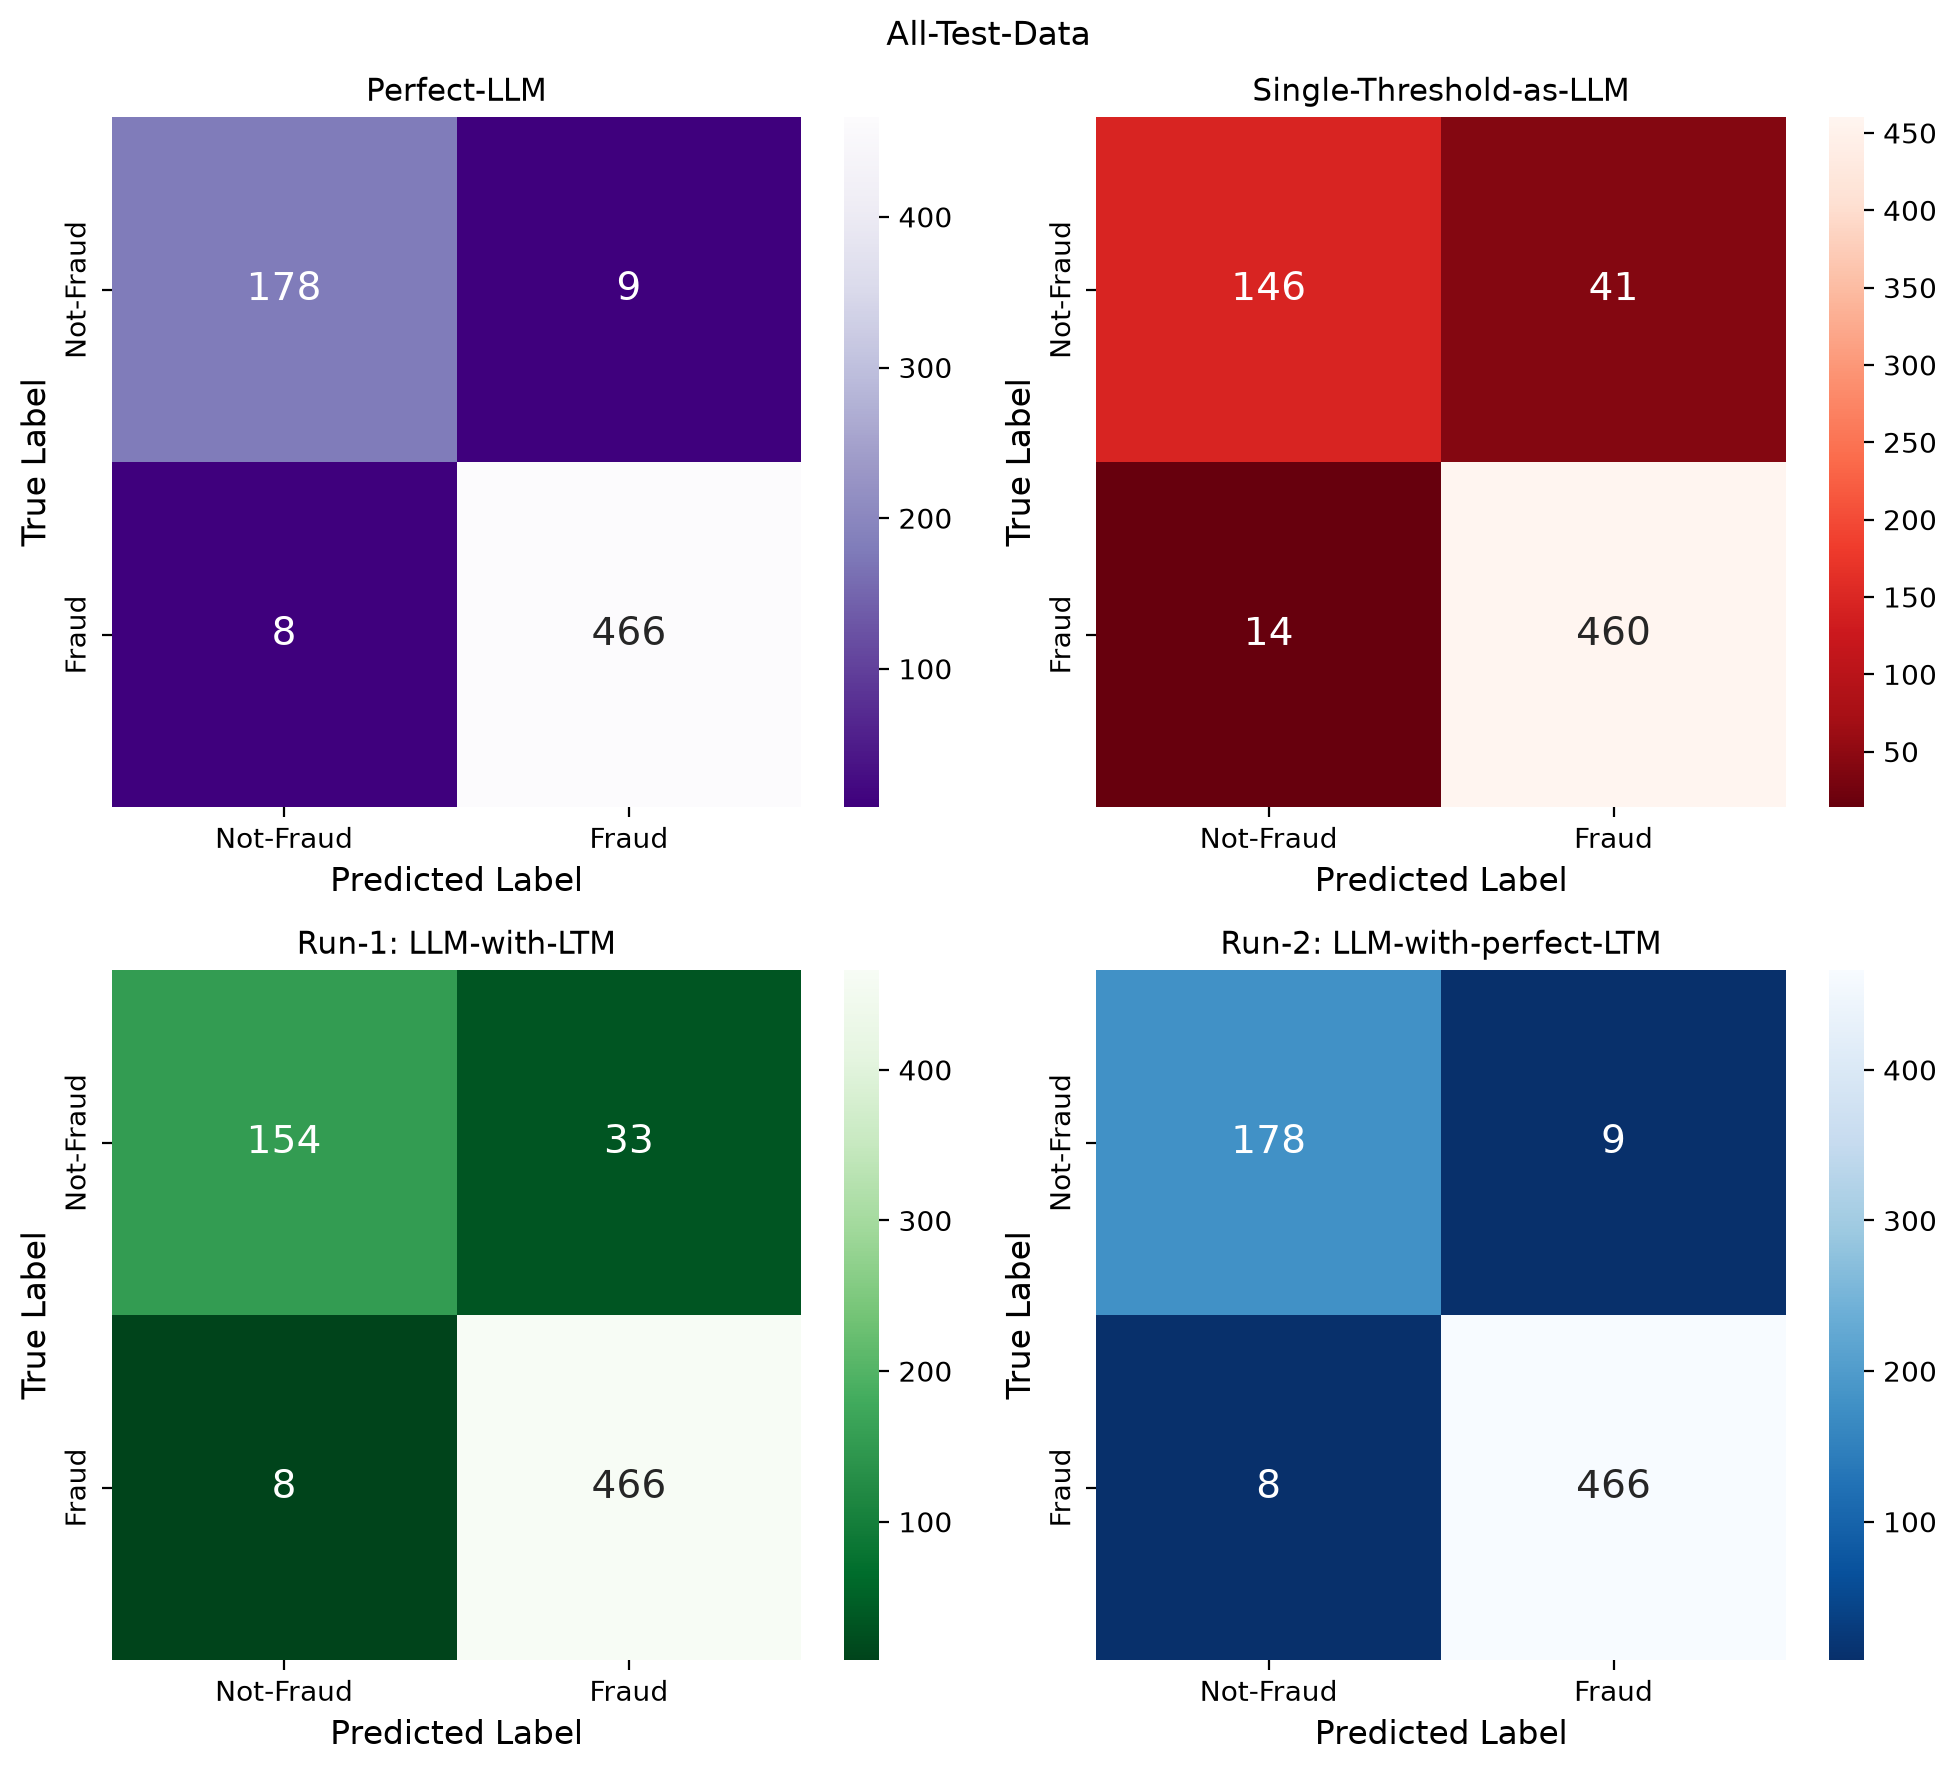

In [28]:
sns_cmaps=['Blues_r','Greens_r', 'Reds_r','Purples_r', 'Oranges_r']
fig, axs = plt.subplots(2,2,figsize=(10,9))
axs=axs.flatten()
#ideal perfect-LLM
df_real_gen['pred_class'] = np.select(get_conditions(df_real_gen, include_llm=False), choices[:2], default=df_real_gen['actual_class'])
metric0=ut.plot_confusion_matrix_from_test_results_transaction_df(df_real_gen,sns_cmaps[3], axs[0], 'Perfect-LLM')

df_real_gen['pred_class'] = np.select(get_conditions(df_real_gen), choices, default=2)
metric1=ut.plot_confusion_matrix_from_test_results_transaction_df(df_real_gen,sns_cmaps[2], axs[1], 'Single-Threshold-as-LLM')

metric2=ut.plot_confusion_matrix_from_test_results_transaction_df(df1,sns_cmaps[1], axs[2], 'Run-1: LLM-with-LTM')

metric3=ut.plot_confusion_matrix_from_test_results_transaction_df(df2,sns_cmaps[0], axs[3], 'Run-2: LLM-with-perfect-LTM')

plt.suptitle(f'All-Test-Data')
plt.tight_layout()
plt.savefig(settings.IMG_DIR/'conf_mat_all_test_data_cmp.png', dpi=600)

In [29]:
metrics_df = pd.DataFrame([metric0, metric1, metric2, metric3])
metrics_df= metrics_df.set_index('Run')
metrics_df = (100*metrics_df).round(2)
metrics_df

,Accuracy,Precision,Recall,F1-Score,F2-Score
Run,,,,,
Perfect-LLM,97.43,98.11,98.31,98.21,98.27
Single-Threshold-as-LLM,91.68,91.82,97.05,94.36,95.95
Run-1: LLM-with-LTM,93.80,93.39,98.31,95.79,97.29
Run-2: LLM-with-perfect-LTM,97.43,98.11,98.31,98.21,98.27


In [30]:
# Markdown version for README
# a= metrics_df.to_markdown(index=True)
# print(a)

### Note
Both Confusion Matrix and numerical data shows that
- FN=8, and FP=9 caused by the Detector and cannot be improved by system unless we find better ML model
- using agentic workflow with dual-threshold at Detector stage plus LLM supported with LTM outperform using a single-threshold (instead of LLM)
- using single-threshold may not perform well for all data, and may need frequent re-tuning
- LLM supported by LTM, where it can decide to Escalate to Human can improve the performance in more reliable way
- Since we emphasize in our prompt, LLM put more attention to FN, and very interestingly it did not add any FN, while the single threshold actually increase FN from 8 to 14, and ofcourse has more FP than LLM (41 vs 33)

In [31]:
#
# LLM test-cases
# initially
tn = 21+57 # (real + gen)
tp = 8 +34 # (real + gen)
fn = 0
fp = 0
#-----
# test-results
fn =0
fp = 33-9
tn = tn - fp
#-----
 # 1. Accuracy
accuracy = (tp + tn) / (tp + tn + fp + fn)
# 2. Precision
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
# 3. Recall (Sensitivity / True Positive Rate)
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
# 4. F1-Score
f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
# 5. F2-Score (beta=2 weighs recall higher than precision)
beta = 2
f2_score = (1 + beta**2) * (precision * recall) / ((beta**2 * precision) + recall) if (precision + recall) > 0 else 0

print(f'accuacy = {accuracy:.2%}')
print(f'precision = {precision:.2%}')
print(f'recall = {recall:.2%}')
print(f'f1_score = {f1_score:.2%}')
print(f'f2_score = {f2_score:.2%}')


accuacy = 80.00%
precision = 63.64%
recall = 100.00%
f1_score = 77.78%
f2_score = 89.74%


### Note
Base on the results of this test for __LLM-Agent__:
1. accuracy is `80%`
2. We have asymmetric recall precision, which cause by our prompt emphasizing on more importance on FN
3. f2-score is about `90%` which is pretty good
4. In our dual threshold optimization for simplicity we assume a single accuracy for LLM-Agent,
5. based on this result in future we can use different recall and precision and re-optimize our dual thresholds

# Analytics

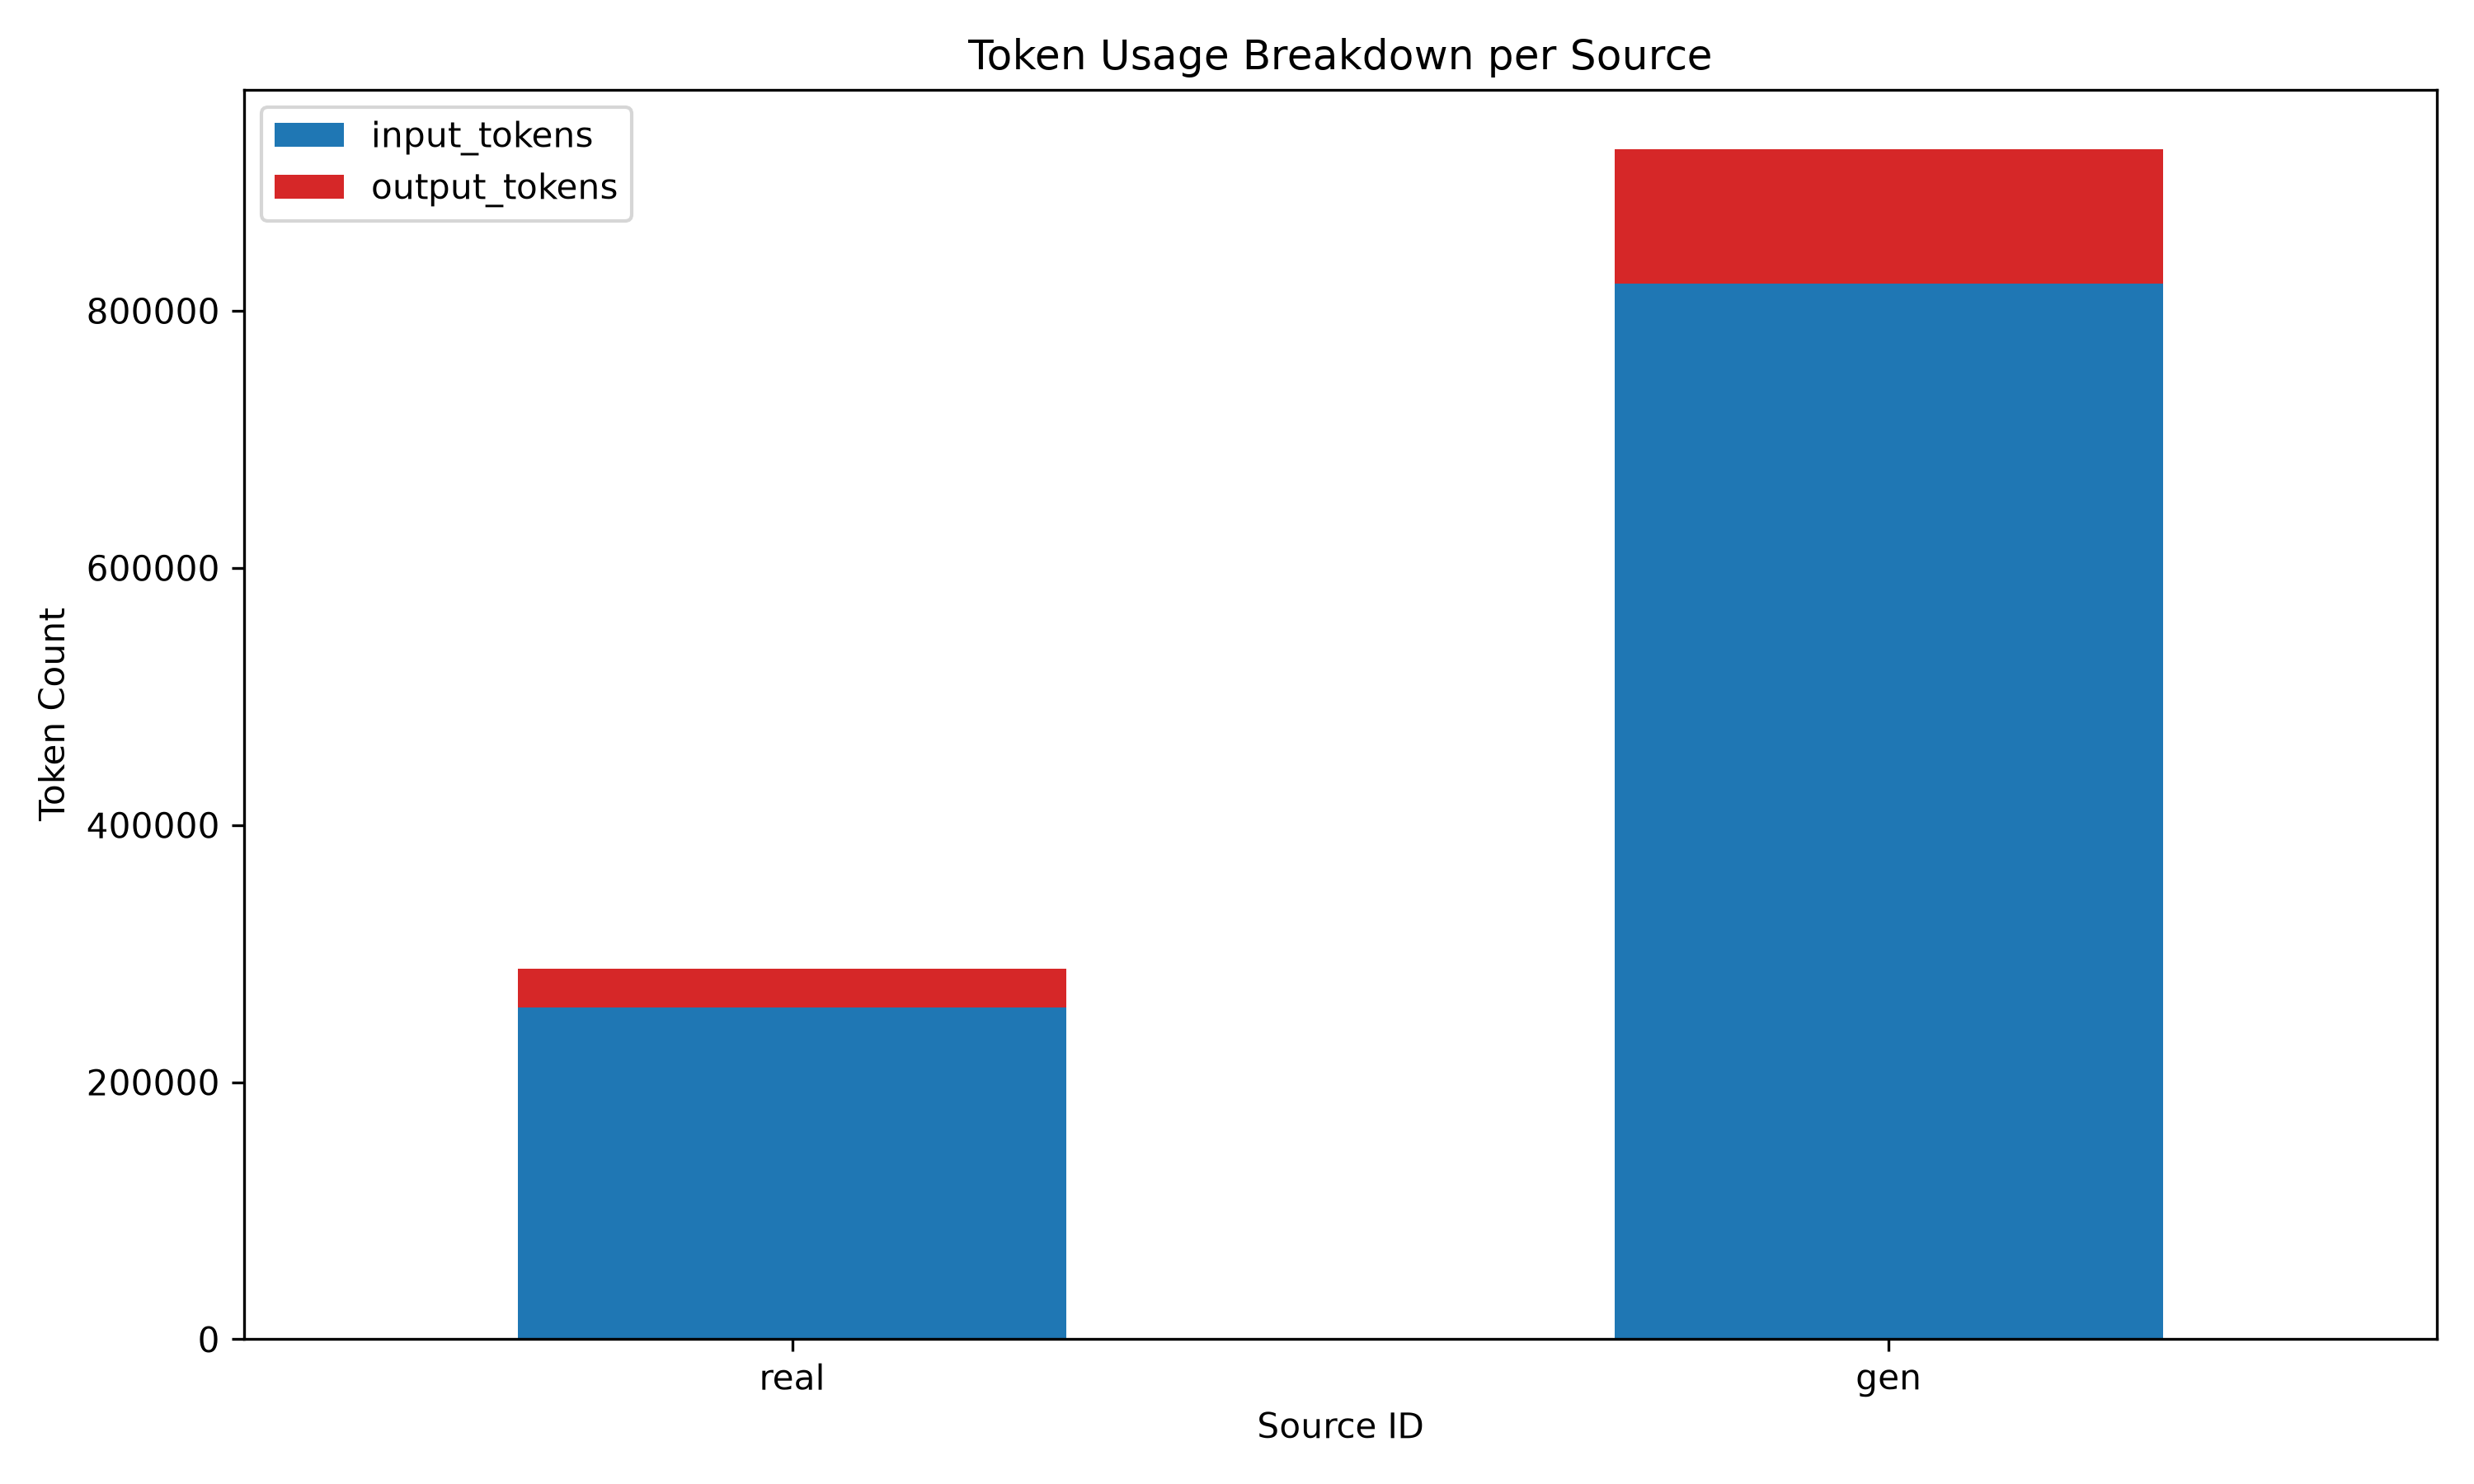

In [32]:
display(Image(filename=settings.IMG_DIR/'token_usage.png', width=1200))

### Note
As shown in __Test Case Count Info__ section above
- Total test-case required LLM with __real__ data is 29
- Total test-case required LLM with __gen__ data is 91
- ratio is about 91/29~3.14
- This can explain the token usage difference on real-data vs gen-data

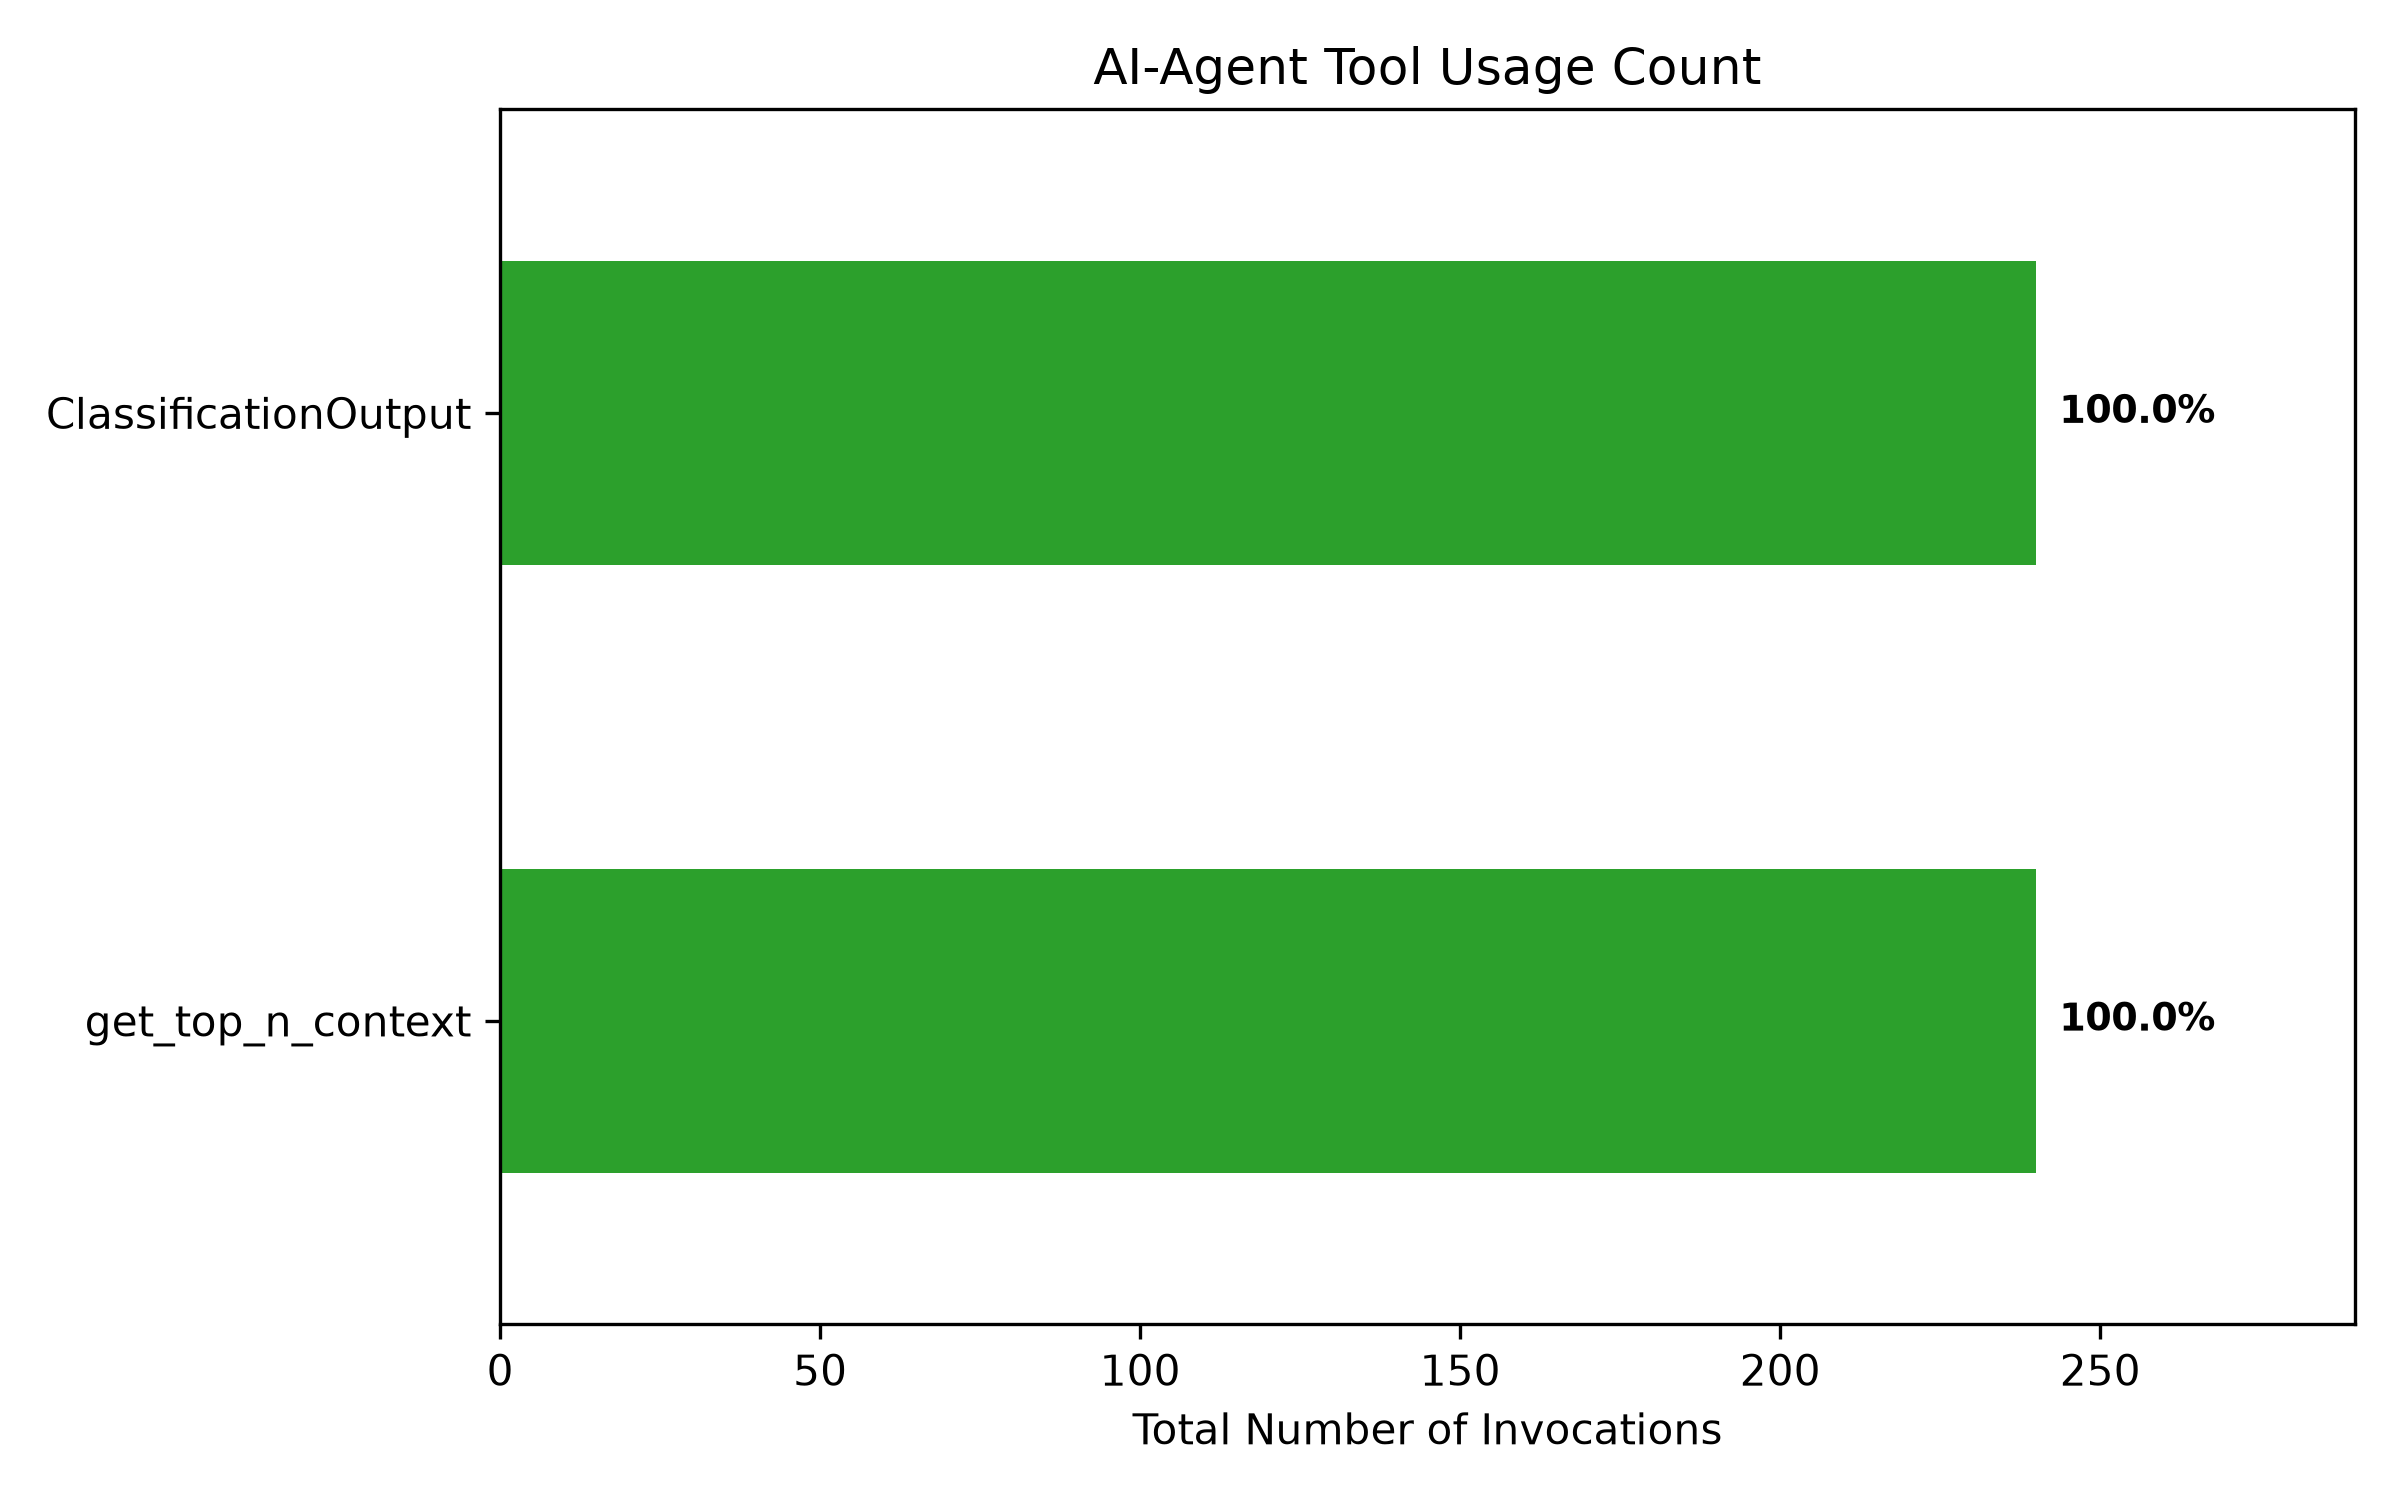

In [33]:
display(Image(filename=settings.IMG_DIR/'tool_usage.png', width=1200))

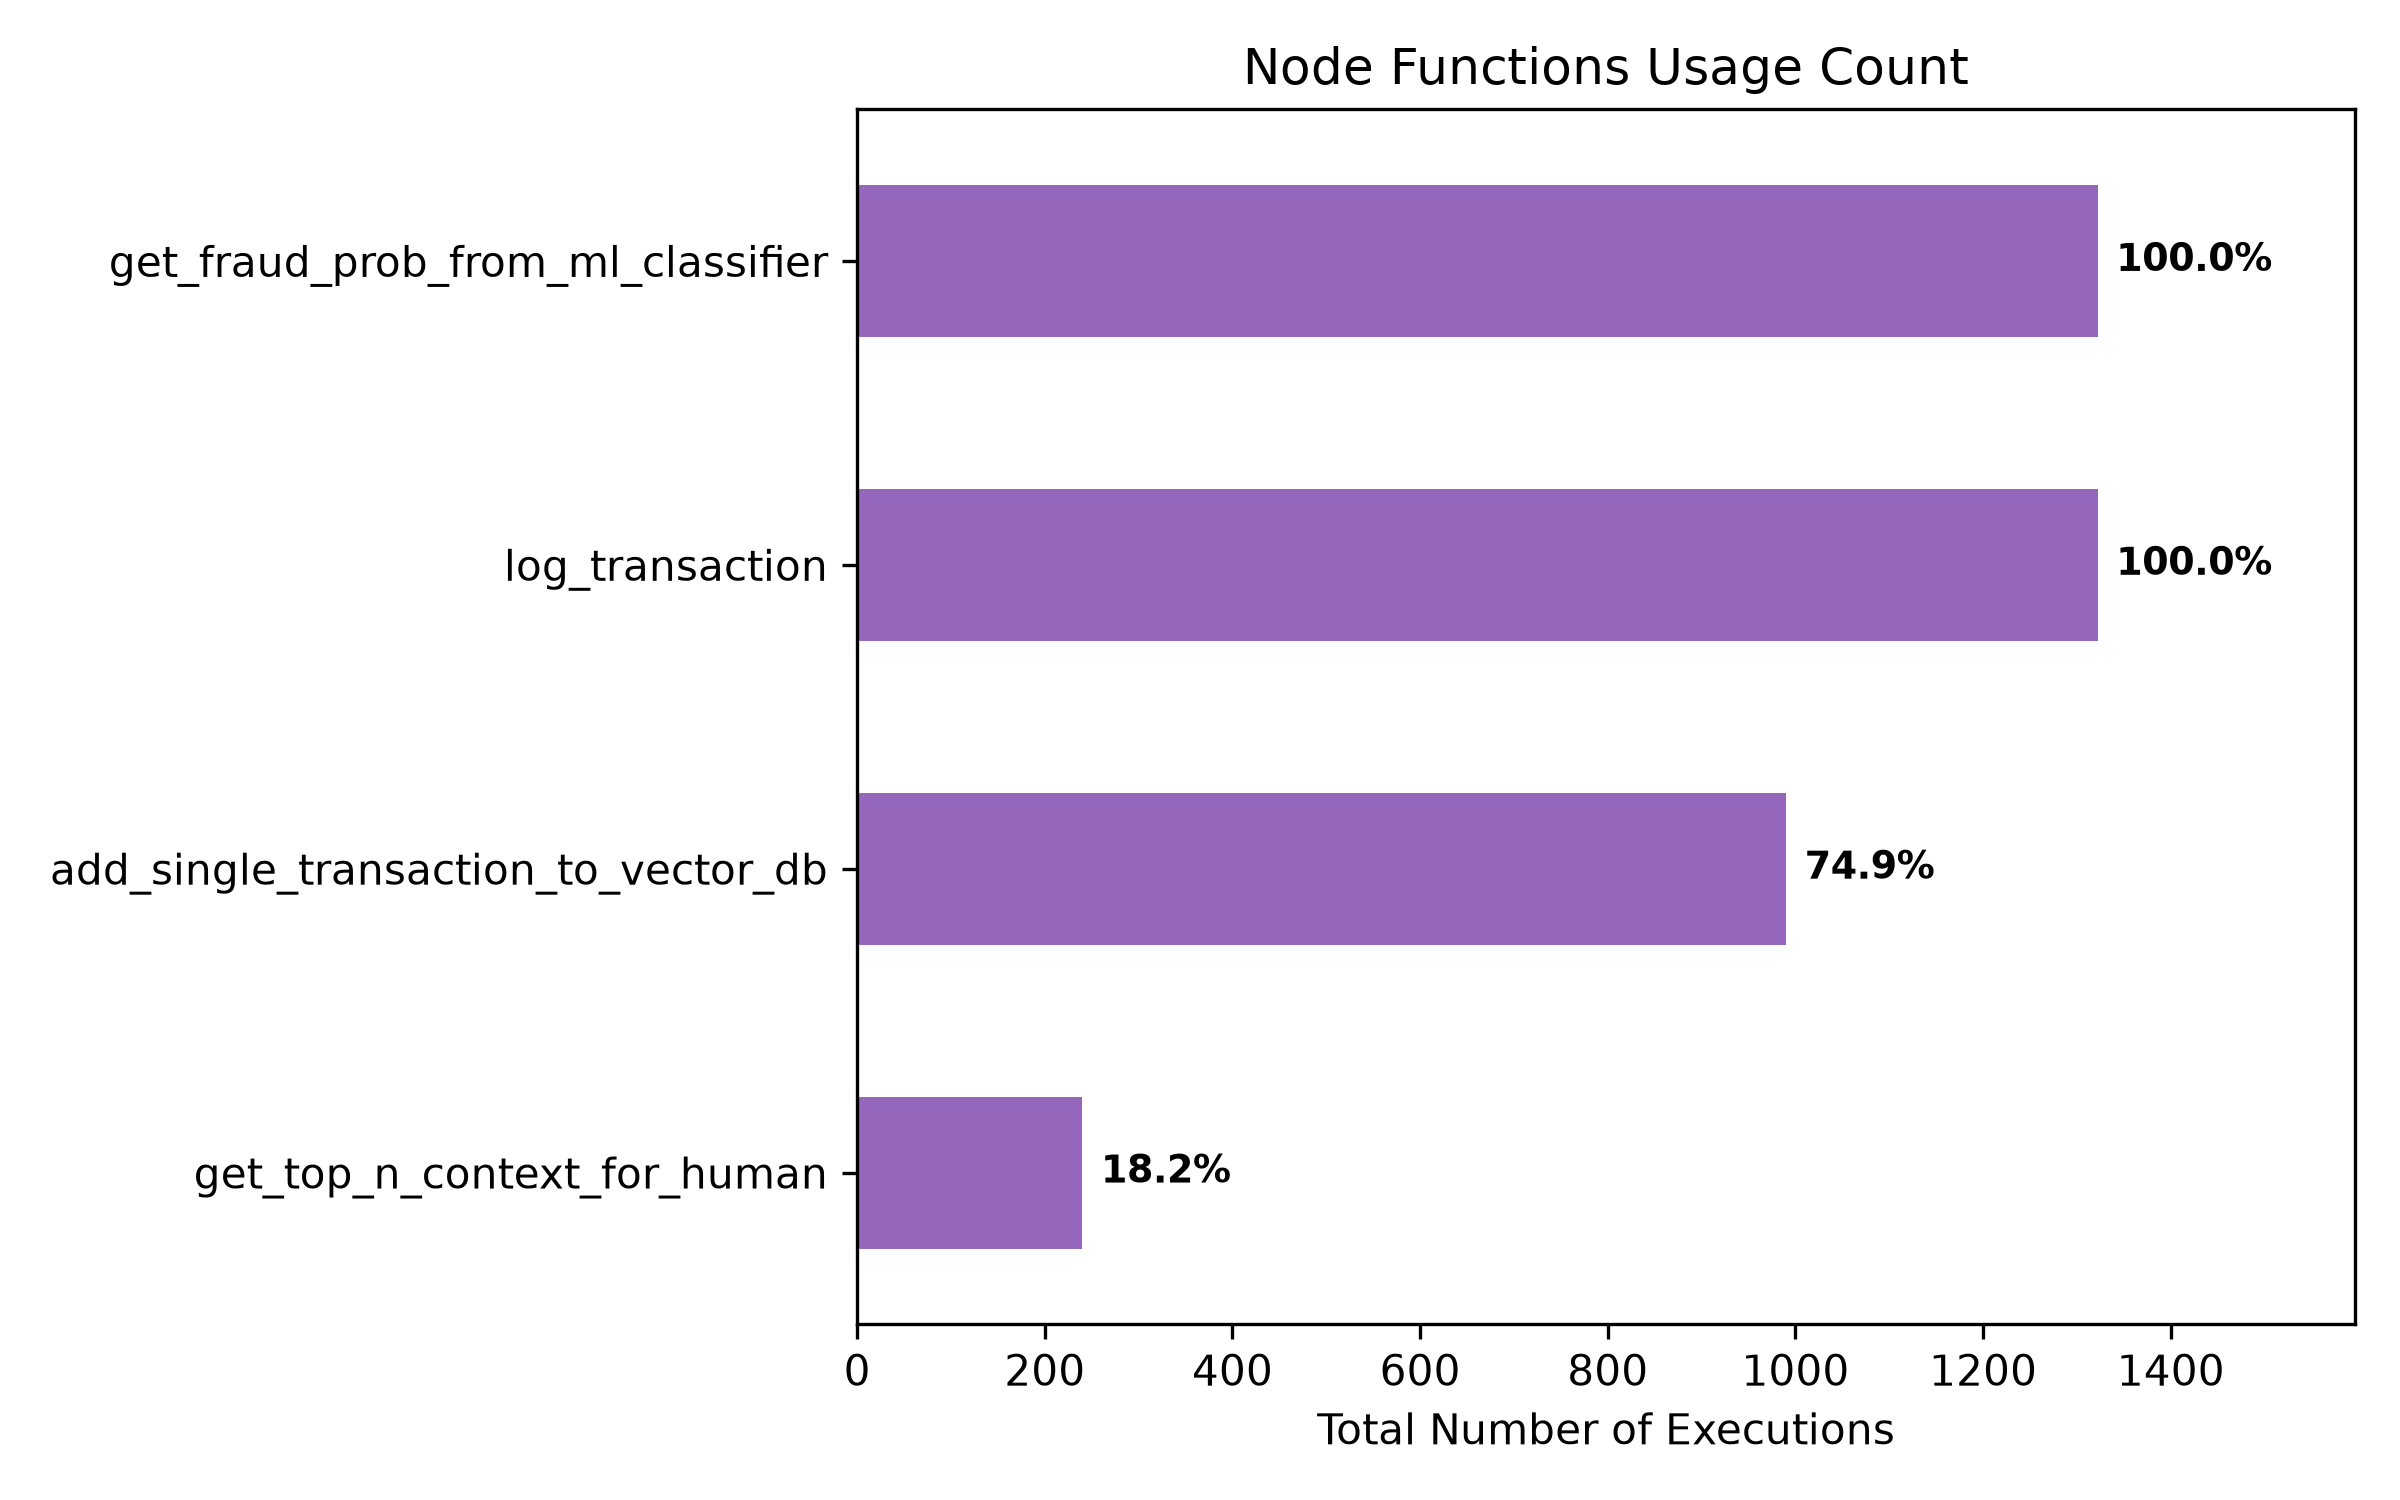

In [34]:
display(Image(filename=settings.IMG_DIR/'func_usage.png', width=1200))

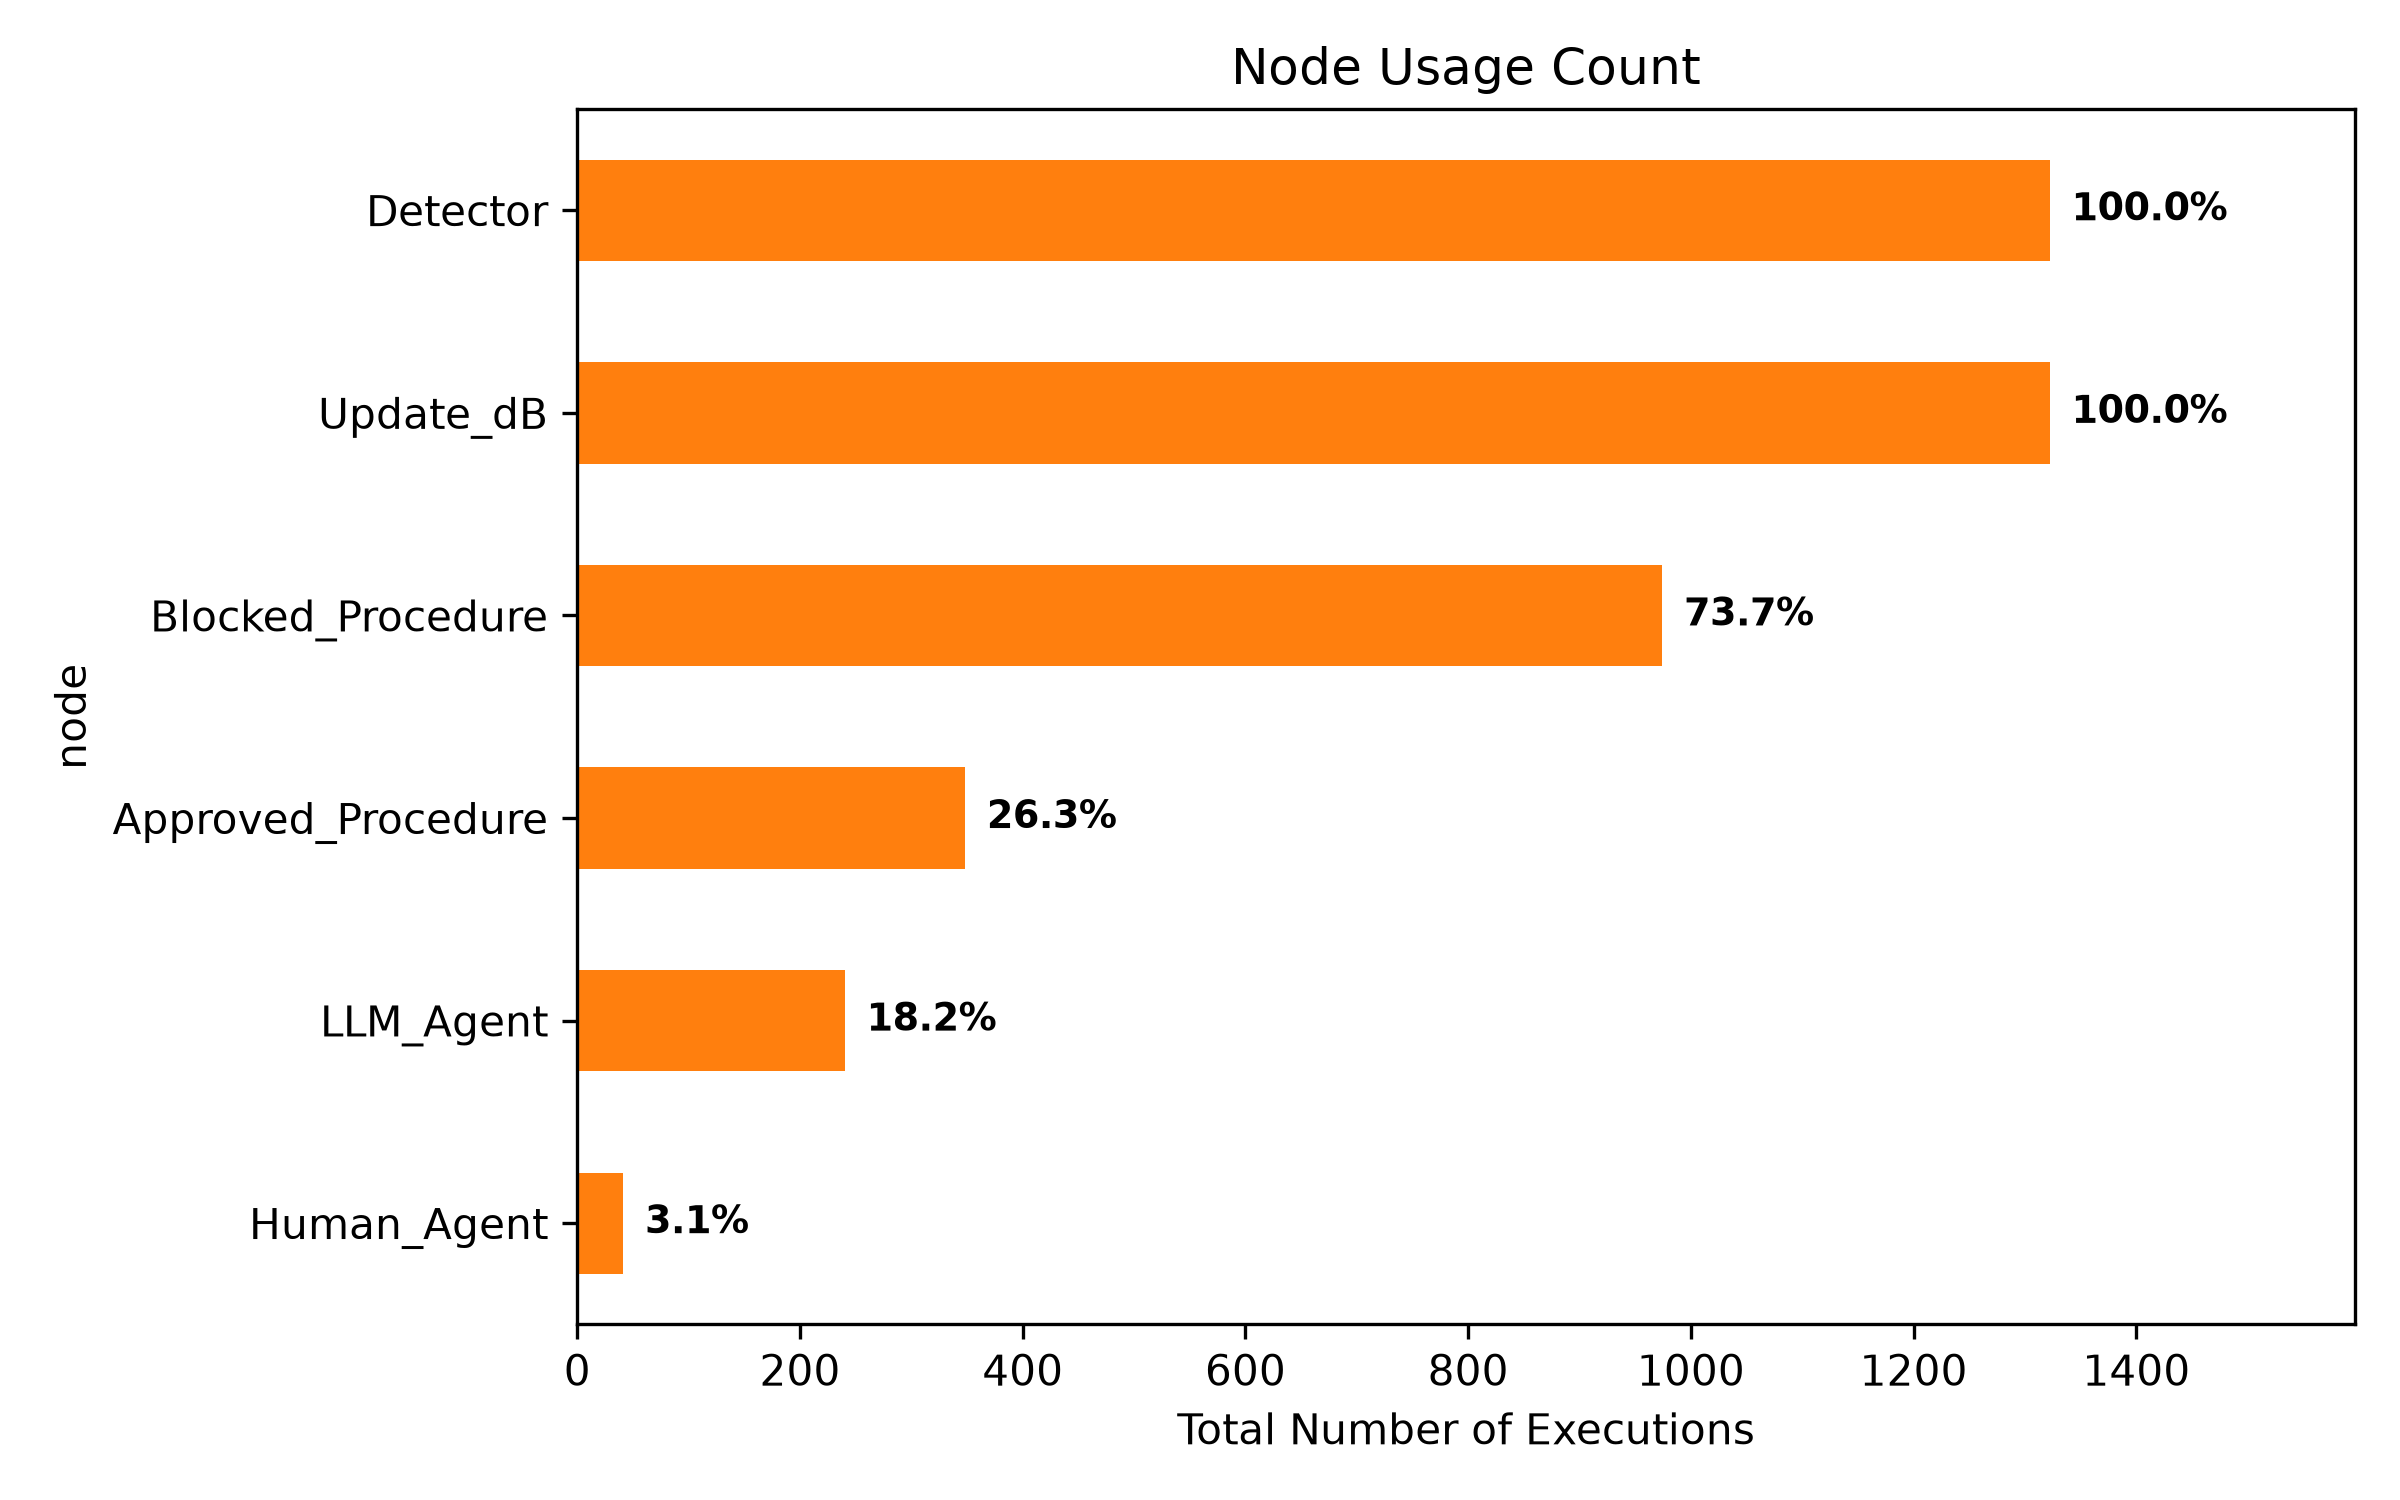

In [35]:
display(Image(filename=settings.IMG_DIR/'node_usage.png', width=1200))

In [36]:
node_usage_df=pd.read_csv(settings.IMG_DIR/'node_usage.csv')
node_usage_df['usage_count%']=(100*node_usage_df['usage_count']/node_usage_df['usage_count'].max()).round(3)
node_usage_df

,node,usage_count,usage_count%
0,Human_Agent,41,3.101
1,LLM_Agent,240,18.154
2,Approved_Procedure,348,26.324
3,Blocked_Procedure,974,73.676
4,Update_dB,1322,100.000
5,Detector,1322,100.000


In [37]:
# Markdown version for README
#a= node_usage_df.to_markdown(index=False)
#print(a)

### Node
- LLM was only involved in `18.2%` of all interaction
- Human was only involved in `3.1%`
- which means LLM Escalate and involved Human in 3.1/18.2~0.17 (`17%`) of its interaction

# Check dB

In [38]:
df_trans = get_transaction_df()
if df_trans is not None:    
    display(df_trans.sample(1))
else:
    print('No transaction dB is created yet, It will be initiate after first run of agentic_system.py')

,index,timestamp,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,HourT,actual_class,pred_class,source_id
931,932,2026-10-10 14:51:53.163167,-1.07382,0.415616,-2.273977,1.536844,-0.758697,-1.670381,-2.37714,0.09037,0.004847,-2.776747,1.428413,-4.482679,-0.709519,-4.610138,0.621338,-4.602713,-7.524188,-2.557104,1.319124,0.227051,0.535542,0.863592,0.450743,-0.144228,-0.205609,-0.539073,0.503418,-0.237807,11.0,5,1,1,real


In [39]:
transaction_data = pd.read_csv(settings.DATA_DIR/settings.DATASET_FILE_CLEANED, nrows=1).loc[0].to_dict()
_ = transaction_data.pop('Class', None)
result_str, result_df= get_top_n_context_for_human(transaction_data, top_n = 5)
if result_df is not None:    
    print(result_str)
    display(result_df)
else:
    print('No LTM dB is created yet, It will be initiate after first run of agentic_system.py')

[doc-1]-id: 239d9c8146, distance: 0.35168, Amount: 290.18, Hour_Block: 8, fraud_prob: 0.909021, actual_class: Fraud
[doc-2]-id: 2ae2d30e30, distance: 0.392566, Amount: 45.03, Hour_Block: 10, fraud_prob: 0.90162, actual_class: Fraud
[doc-3]-id: 4ea3d8a403, distance: 0.413666, Amount: 208.58, Hour_Block: 6, fraud_prob: 0.95003, actual_class: Fraud
[doc-4]-id: 5d0e44fa74, distance: 0.452212, Amount: 67.22, Hour_Block: 8, fraud_prob: 0.040838, actual_class: Legit
[doc-5]-id: ee0c32bc01, distance: 0.506555, Amount: 529.0, Hour_Block: 0, fraud_prob: 0.940552, actual_class: Fraud



,id,distance,Amount,Hour_Block,fraud_prob,actual_class
0,239d9c8146,0.351680,290.18,8,0.909021,Fraud
1,2ae2d30e30,0.392566,45.03,10,0.901620,Fraud
2,4ea3d8a403,0.413666,208.58,6,0.950030,Fraud
3,5d0e44fa74,0.452212,67.22,8,0.040838,Legit
4,ee0c32bc01,0.506555,529.00,0,0.940552,Fraud


In [40]:
from tools.checkpoint_db_analytics import get_checkpoint_df
df_checkpoint = get_checkpoint_df()
if df_checkpoint is not None:
    print(f'Checkpoint-dB: colums= {df_checkpoint.columns.to_list()}') # ['thread_id', 'checkpoint_ns', 'checkpoint_id', 'parent_checkpoint_id', 'type', 'checkpoint', 'metadata']
    print(f'Checkpoint-dB: shape={df_checkpoint.shape}')
    display(df_checkpoint.sample(1))
else:
    print('No Checpoint dB is created yet, It will be initiate after first run of agentic_system.py')

Checkpoint-dB: colums= ['thread_id', 'checkpoint_ns', 'checkpoint_id', 'parent_checkpoint_id', 'type', 'checkpoint', 'metadata']
Checkpoint-dB: shape=(8091, 7)


thread_id                                       checkpoint_ns  \
2762      real  agent_LLM_RAG:8d5738af-2cd7-fddc-cc11-8c1f960e6b64   

                             checkpoint_id parent_checkpoint_id     type  \
2762  1f1c4b2b-2ce3-6e84-bfff-cd731bf96430                 None  msgpack   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               

# Check Log files
- logs are saved in __jsonl__ format for easy offline parsing

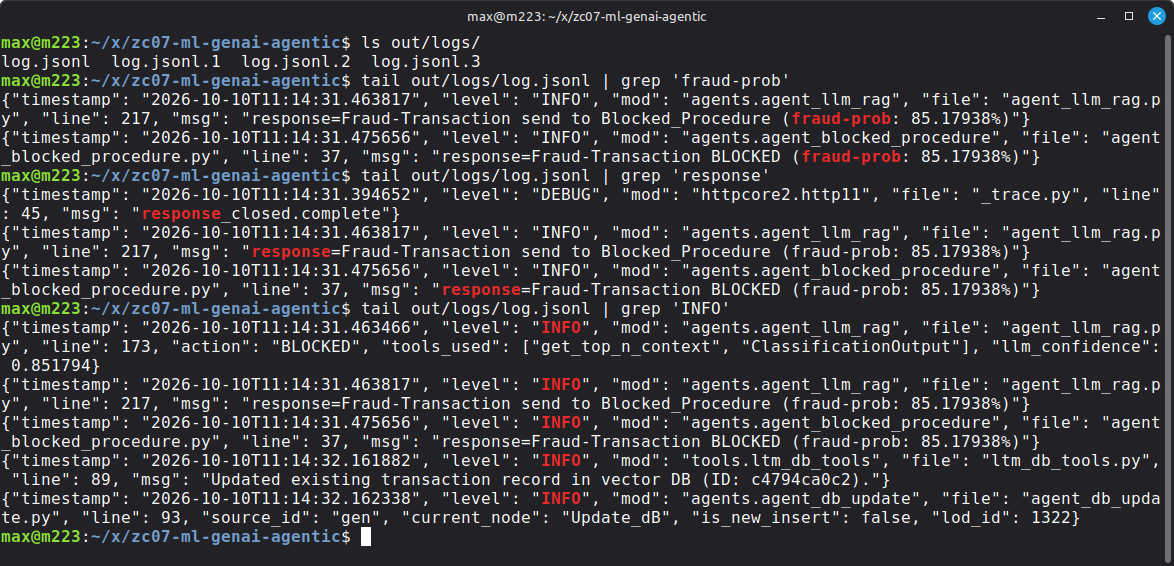

In [41]:
display(Image(filename=settings.IMG_DIR/'sample-log.png', width=1200))

### Elapsed Time

In [42]:
# Calculate elapsed time
total_elapsed_time = time.time() - notebook_start_time
minutes = int(total_elapsed_time // 60)
seconds = total_elapsed_time % 60
print(f"Total Notebook Execution Time: {minutes} minutes and {seconds:.2f} seconds")

Total Notebook Execution Time: 0 minutes and 19.78 seconds


# Summary

1. In step-1
   - Used Hour/2 instead of time (feature engineering)
   - Trained and compared XGBoost classifier without oversampling using cost-sensitive learning, and with oversampling (using SMOTE/BorderLine SMOTE, Generative Modes: TVAE, CTGAN). Model with CTGAN and no oversampling were promising
2. In Step-2
   - We Trained generative models TVAE and CTGAN on full dataset
   - Compare them with different visual and numerical methods, and select CTGAN model with ML-classifier oversampled with CTGAN
3. In Step-3
   - We use both real-dataset and generated-dataset, and find optimal dual thresholds  by defining a proper cost function
   - We define a dataset for agentic-workflow evaluation, and split it into train and test dataset
   - We define a Vector-dB with proper embedding vectors (extracted from transaction data)
4. In Step-4
    - We use the train-dataset to initialize a vector database as Long-Term Memory
    - We use the test-dataset to evaluate our agentic workflow
5. Results show that:
    - Using agentic workflow have better performance
    - Also using agentic workflow is more reliable that having a single-threshold that may need keep re-tuning
    - After first detector stage using ML-classifier with dual thresholds, only `18.2%` need Escalation to LLM-Agent
    - LLM-Agent can handle `83%` of its task, and only need to Escalate `17%` of its task to Human (`3.1%` of total task handle by system)
    - System performance (called __Run-1__: when we load train-dataset to LTM, and test based on test-dataset) is about __F2-Score = `97.3%`__
6. We also provide analytic of the agentic workflow with different visualization
7. Future work:
   - When we optimize the dual thresholds for simplicity we use  one parameter as agent-accuracy
   - we use this accuracy as both recall and precision
   - based on the limited number of test here we find the LLM-agent metric values (accuracy, recall, precision, f1 and f2 scores)
   - Obviously based on our prompt which put more importance on FN, we end up having high recall `100%` and low precision `63.64%` for LLM-Agent
   - This will create good __F2-Score__ as the target metric (LLM-Agent: F2-Score = `89.74%`)
   - This results suggest that we have to modify our dual-threshold optimization to consider different recall/precision for agent
   - Also we need to collect more data for better estimation of these recall/precision then re-optimized our dual-thresholds